# 2. Reserva del conjunto de prueba (partición por bloques espaciales)

*Autores: María Carolina Cantillo Orozco (200179105) y Juan Camilo Oñoro Araujo (200177329)*

```{admonition} Qué hace este capítulo
:class: tip
**Pregunta que responde:** ¿cómo separar un conjunto de prueba que sea un
"examen justo" para el modelo?

**Datos:** las **322 418 viviendas con coordenadas** (universo de modelado,
sección 1.7), incluidas las 43 594 ubicadas por el centroide de su manzana.
Las 10 300 que siguen sin coordenadas no se pueden asignar a una zona y se
guardan aparte para medir su sesgo en el capítulo 3.

**Conceptos nuevos:** estratificar, agrupar, bloque espacial y divergencia
de Jensen-Shannon (todos se explican abajo; ver también la Guía de
lectura).

**Sale de aquí:** la etiqueta `train` / `test` de cada vivienda, que todos
los capítulos siguientes leen del mismo archivo.
```

Las instrucciones del proyecto exigen **reservar el conjunto de prueba antes
de tomar cualquier decisión basada en los datos** (imputación,
transformaciones, selección de variables, umbrales de outliers). La razón es
la misma por la que un profesor no muestra el examen antes de la clase: si
las decisiones se toman mirando la prueba, la nota final ya no mide lo que
el modelo aprendió. Además, la partición debe respetar la estructura de los
datos. Aquí hay tres estructuras que respetar a la vez:

| Estructura | Ejemplo | Riesgo si se ignora | Respuesta |
|---|---|---|---|
| Desbalance de clases (~8:1 entre estrato 1 y estrato 6 en las filas limpias, cap. 1) | hay unas 108 000 viviendas de estrato 1 y solo 13 000 de estrato 6 | por azar, un fold podría quedar casi sin estratos 5 o 6 | **estratificar**: que cada fold tenga proporciones de estrato parecidas |
| Varias filas por entidad | los 200 apartamentos de un conjunto comparten estrato y son casi idénticos | el modelo "reconoce" el conjunto en vez de aprender | **agrupar**: un predio matriz va completo a un solo lado |
| Autocorrelación espacial fuerte | una casa de estrato 1 suele estar rodeada de casas de estrato 1 | test optimista: cada vivienda de prueba tiene vecinas casi iguales en entrenamiento | **bloques espaciales**: se separan zonas completas de la ciudad |

La herramienta que cubre las tres es una partición **estratificada por
grupos** (la lógica de `StratifiedGroupKFold`) usando como grupo un **bloque
espacial** de 2 km × 2 km. Un predio matriz siempre cae completo en un
bloque, porque todas sus unidades comparten el mismo centroide. Los bloques
se reparten en 5 grupos (*folds*) con proporciones de estrato parecidas, y
uno de ellos (~20 % de las filas) se reserva como prueba. Referencias: notas
de clase 9.1.9 (`GroupKFold`) y 9.1.11 (Spatial Block CV; Roberts et al.,
2017; Valavi et al., 2019).

```{admonition} Por qué una función propia y no StratifiedGroupKFold
:class: tip
Los folds se generan con `folds_estratificados_por_grupo`, una función propia
de `src/particion.py`. Aplica el **mismo algoritmo voraz** de
`StratifiedGroupKFold` de scikit-learn (se barajan los bloques con una
semilla, se ordenan de más a menos desbalanceado y cada bloque va al fold
donde las proporciones de estrato entre folds quedan más parecidas), pero el
barajado usa `numpy.random.default_rng` con semilla fija. El motivo es la
**reproducibilidad entre versiones de scikit-learn**: con
`StratifiedGroupKFold(shuffle=True)` la asignación de bloques a folds cambia
según la versión instalada, y al ejecutar el libro en Google Colab, con otra
versión, el fold de test quedó dominado por el estrato 3 y casi sin estratos
4–6. Una partición que depende de la versión instalada no es reproducible;
con la función propia, la misma semilla da los mismos folds en cualquier
máquina (detalles en el docstring del módulo). La misma función genera los
folds de la validación cruzada espacial del capítulo 10.
```

```{note}
Este capítulo solo separa los bloques. La otra protección espacial, el
**buffer** (franja de exclusión de 1 km entre entrenamiento y prueba, ver la
Guía de lectura), se decide más adelante, en el capítulo 8, a partir de
cómo se parecen las viviendas según la distancia, calculado **solo con
entrenamiento**. Se aplica al entrenar el modelo final (capítulo 10). Así su
tamaño también es una decisión tomada sin mirar el conjunto de prueba.
```

In [1]:
# Celda de configuración: librerías y módulos propios. Además de los del cap. 1 se
# importa P (particion.py), que implementa la partición por bloques espaciales, y
# scipy.stats para comparar la distribución del estrato entre train y test.
import sys
import warnings
from pathlib import Path

# Raíz del libro en sys.path para importar src/ desde notebooks/ o desde la raíz.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from src import config as C      # SEED, TAM_BLOQUE_KM, N_FOLDS y rutas
from src import graficos as G    # estilo de figuras y ejes de mapa
from src import limpieza as L    # mismas reglas deterministas del cap. 1
from src import particion as P   # bloques espaciales + folds estratificados por grupo (función propia)

G.estilo()
C.aviso_sintetico()   # alerta si se corre con el CSV sintético de prueba
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
# Se reconstruye el dataset limpio con las mismas reglas del cap. 1 y se separa en
# filas con y sin coordenadas: solo las ubicables pueden asignarse a un bloque
# espacial, así que ellas forman la población de modelado. Las coordenadas
# incluyen las del paso 6 del embudo (centroide de la manzana, sección 1.7.2).
df = L.cargar_datos_limpios()
# reset_index deja índices 0..n-1, necesarios porque la partición usa posiciones.
con = df[df["tiene_coordenadas"]].reset_index(drop=True)
sin = df[~df["tiene_coordenadas"]].reset_index(drop=True)
n_manz = int(con["ubicado_por_manzana"].sum())
print(f"Filas limpias: {len(df):,}")
print(f"  con coordenadas (población de modelado): {len(con):,} ({100 * len(con) / len(df):.1f}%)")
print(f"    propias o del edificio matriz:         {len(con) - n_manz:,} ({100 * (len(con) - n_manz) / len(df):.1f}%)")
print(f"    centroide de la manzana (paso 6):      {n_manz:,} ({100 * n_manz / len(df):.1f}%)")
print(f"  sin coordenadas (no ubicables):          {len(sin):,} ({100 * len(sin) / len(df):.1f}%)")

Filas limpias: 332,718
  con coordenadas (población de modelado): 322,418 (96.9%)
    propias o del edificio matriz:         278,824 (83.8%)
    centroide de la manzana (paso 6):      43,594 (13.1%)
  sin coordenadas (no ubicables):          10,300 (3.1%)


Las viviendas ubicadas por el centroide de su manzana entran a la partición
como cualquier otra: todas las de una manzana caen en el mismo bloque. Las
filas que siguen **sin coordenadas** no pueden asignarse a ningún bloque
espacial, así que quedan fuera del modelado (la decisión se justificó en la
sección 1.7). Se guardan aparte para cuantificar el sesgo que esto introduce
(capítulo 3.3).

In [3]:
# Reserva del conjunto de prueba ANTES de cualquier decisión aprendida de los datos.
# particion_test_espacial arma una grilla de bloques de 2 km x 2 km sobre (x_km, y_km)
# y toma 1 de 5 folds de folds_estratificados_por_grupo como test (~20 %): agrupa
# por bloque (nunca parte uno) y estratifica por estrato. La semilla fija (generador
# de numpy) la hace reproducible, sin depender de la versión de scikit-learn.
particion, bloques = P.particion_test_espacial(con, tam_km=C.TAM_BLOQUE_KM, seed=C.SEED)
con["bloque"] = bloques                    # id de bloque: se reutiliza en la CV y el bootstrap
con["particion"] = particion.to_numpy()    # etiqueta 'train' / 'test' por fila
# Proporción real de filas en cada conjunto (no es exactamente 20 % porque los
# bloques tienen tamaños distintos).
print(con["particion"].value_counts(normalize=True).round(3).to_dict())

{'train': 0.798, 'test': 0.202}


## Verificaciones de la partición

Una partición se verifica en tres frentes: (1) que ningún predio matriz
quede repartido entre entrenamiento y prueba, (2) que las proporciones de
estrato sean parecidas en ambos lados y (3) que no haya entidades
compartidas. En este libro "edificio" equivale a predio matriz (sección
1.3).

Primero, si algún edificio aparece en ambos conjuntos es porque sus unidades tienen
centroides distintos (unas con terreno propio y otras propagadas) y cayeron
en bloques distintos; si ocurre, se reasigna todo el edificio al conjunto de
prueba para que no quede partido.

In [4]:
# Control de integridad: un edificio no debe quedar con unidades en train y en test,
# porque el modelo "reconocería" el edificio (sus unidades comparten estrato).
# Se cuenta en cuántos conjuntos distintos aparece cada edificio.
comp = con.groupby("npn_edificio")["particion"].nunique()
partidos = comp[comp > 1].index
if len(partidos):
    # Se mueve el edificio completo a test. Moverlo a train también eliminaría
    # la fuga; lo importante es que la regla sea determinista, no mire etiquetas
    # y afecte a muy pocas unidades (con los datos reales, un solo edificio).
    con.loc[con["npn_edificio"].isin(partidos), "particion"] = "test"
    print(f"Se movieron a test {len(partidos)} edificios que estaban partidos.")
else:
    print("Ningún edificio quedó partido entre train y test.")

Se movieron a test 1 edificios que estaban partidos.


In [5]:
# Resumen por conjunto: filas, bloques y edificios distintos. Muestra que la
# partición se hizo por entidades (bloques/edificios) y no por filas sueltas.
resumen = con.groupby("particion").agg(filas=(C.OBJETIVO, "size"), bloques=("bloque", "nunique"),
                                       edificios=("npn_edificio", "nunique"))
resumen["% filas"] = 100 * resumen["filas"] / resumen["filas"].sum()
resumen

,filas,bloques,edificios,% filas
particion,,,,
test,65145,7,31178,20.205
train,257273,34,134776,79.795


In [6]:
# ¿Quedó bien estratificada la partición? Se compara la distribución del estrato
# en train y test con un chi² (significancia) y con la divergencia de Jensen-Shannon
# (magnitud): con n tan grande el chi² casi siempre rechaza, así que se lee la JS.
# % de cada estrato dentro de cada conjunto (normalize="columns": cada columna suma 100).
dist = (pd.crosstab(con[C.OBJETIVO], con["particion"], normalize="columns") * 100)
dist.index = [C.NOMBRES_CLASES[i] for i in dist.index]
dist["diferencia (p.p.)"] = dist["test"] - dist["train"]   # puntos porcentuales
# El chi² se calcula sobre los CONTEOS (la tabla sin normalizar), no sobre porcentajes.
chi2, p, gl, _ = stats.chi2_contingency(pd.crosstab(con[C.OBJETIVO], con["particion"]))
# Jensen-Shannon: promedio de las divergencias KL de cada distribución a su mezcla m.
# Es simétrica y acotada (0 = idénticas; máximo ln 2 con logaritmo natural).
pt, pq = dist["train"] / 100, dist["test"] / 100
m = (pt + pq) / 2
js = 0.5 * (pt * np.log(pt / m)).sum() + 0.5 * (pq * np.log(pq / m)).sum()
print(f"Chi2 = {chi2:,.1f} (gl={gl}), p = {p:.3g}  |  divergencia de Jensen-Shannon = {js:.4f}")
dist

Chi2 = 3,296.2 (gl=5), p = 0  |  divergencia de Jensen-Shannon = 0.0096


particion,test,train,diferencia (p.p.)
1 Bajo-bajo,35.446,30.020,5.425
2 Bajo,20.250,22.688,-2.438
3 Medio-bajo,19.114,22.917,-3.802
4 Medio,18.804,14.357,4.447
5 Medio-alto,5.168,5.193,-0.024
6 Alto,1.217,4.825,-3.608


```{admonition} Cómo leer esto
:class: note
Se usan dos medidas complementarias:

- **Prueba χ² (chi-cuadrado):** pregunta si las proporciones de estrato de
  train y test podrían ser iguales y diferir solo por azar. Con cientos de
  miles de filas casi siempre sale significativa aunque las diferencias sean
  mínimas (ver "tamaño de efecto frente a p-valor" en la Guía de lectura).
- **Divergencia de Jensen-Shannon (JS):** mide **cuánto** se diferencian
  dos distribuciones. Vale 0 si son idénticas y como máximo ln 2 ≈ 0.69 si
  no comparten nada. *Ejemplo:* si train tuviera 50 % de estrato 1 y 50 % de
  estrato 2 y test 49 % y 51 %, la JS sería ≈ 0.00005; si test fuera 100 %
  estrato 6, sería 0.69.

Lo que importa es la **magnitud**: diferencias de pocos puntos porcentuales
y una JS cercana a 0 indican que train y test tienen proporciones de estrato
comparables. Como la partición es por zonas de la ciudad, es imposible que
sean idénticas: el estrato depende del lugar.
```

```{admonition} Resultado con los datos reales
:class: important
- De las 332 718 filas limpias, **322 418 (96.9 %)** tienen coordenadas y
  forman la población de modelado: 278 824 con coordenadas propias o de su
  edificio matriz y **43 594 (13.1 %) ubicadas por el centroide de su
  manzana** (sección 1.7.2). Las **10 300 (3.1 %)** que siguen sin coordenadas
  quedan fuera (su perfil se analiza en el cap. 3).
- **Test: 65 145 filas (20.2 %) en 7 bloques y 31 178 edificios. Train:
  257 273 filas (79.8 %) en 34 bloques y 134 776 edificios.** Solo 1
  edificio quedó partido entre dos bloques y se movió completo a test; tras
  eso no hay ningún edificio ni predio compartido (el único bloque
  "compartido" es el de ese edificio movido).
- **La partición cambió respecto a la versión sin ubicación por manzana.**
  La grilla de bloques es la misma, pero las viviendas recuperadas (casi
  todas de estratos 1 y 2, en el sur) cambian los conteos por clase de cada
  bloque, y el algoritmo voraz de la estratificación asigna los bloques a
  otros folds: de los 7 bloques de test, solo 3 coinciden con los de la
  versión anterior. Por eso las cifras de test de este libro no se comparan
  una a una con las de la versión anterior; las de la validación cruzada,
  que rota todas las zonas, son más comparables.
- Las proporciones difieren pocos puntos (divergencia de Jensen-Shannon =
  **0.010**, prácticamente 0; el χ² = 3 296 es significativo solo por el
  tamaño de muestra). Las diferencias en los estratos 1 a 5 no pasan de
  ±5.4 puntos porcentuales (test tiene más estrato 1: 35.4 % frente a
  30.0 %); la relevante está en el **estrato 6: 1.2 % en test frente a 4.8 %
  en train** (≈ 790 casos en test). El estrato 6 está concentrado en pocos
  bloques del norte, y el fold que quedó como test tiene pocos de ellos.
  Consecuencia: las métricas por clase del estrato 6 en test serán
  inestables y sus intervalos de confianza anchos (cap. 10). No se
  "corrige" moviendo bloques a mano, porque eso sería elegir el test mirando
  sus etiquetas; se reporta como limitación y se compensa con la validación
  cruzada espacial en train, que sí rota todas las zonas.
- **147 manzanas** tienen viviendas en train y en test. No es una fuga
  (dos manzanas vecinas también se parecen) y no la causa la ubicación por
  manzana: las 147 ya quedarían partidas contando solo las viviendas con
  coordenadas propias. Son manzanas que cruza el borde de un bloque de 2 km.
```

In [7]:
# Auditoría de fuga por entidades: cuenta edificios, predios y bloques que aparecen
# a la vez en train y en test (intersección de conjuntos). Lo esperado es 0 edificios
# y 0 predios; los bloques compartidos solo pueden venir de edificios movidos a test.
fugas = {
    "edificios (NPN 22 díg.) en train y test": len(set(con.loc[con.particion == "train", "npn_edificio"].dropna())
                                                   & set(con.loc[con.particion == "test", "npn_edificio"].dropna())),
    "predios (NPN 30 díg.) en train y test": len(set(con.loc[con.particion == "train", "numero_predial_nacional"].dropna())
                                                  & set(con.loc[con.particion == "test", "numero_predial_nacional"].dropna())),
    "bloques en train y test (solo por edificios movidos)": len(set(con.loc[con.particion == "train", "bloque"])
                                                                & set(con.loc[con.particion == "test", "bloque"])),
}
# Manzanas con viviendas a ambos lados: no es una fuga (dos manzanas vecinas
# también se parecen), pero se reporta porque las viviendas recuperadas usan el
# centroide de su manzana y podrían caer en un bloque distinto al de sus vecinas.
fugas["manzanas (NPN 17 díg.) en train y test"] = len(
    set(con.loc[con.particion == "train", "npn_manzana"].dropna())
    & set(con.loc[con.particion == "test", "npn_manzana"].dropna()))
pd.Series(fugas, name="entidades compartidas").to_frame()

,entidades compartidas
edificios (NPN 22 díg.) en train y test,0
predios (NPN 30 díg.) en train y test,0
bloques en train y test (solo por edificios movidos),1
manzanas (NPN 17 díg.) en train y test,147


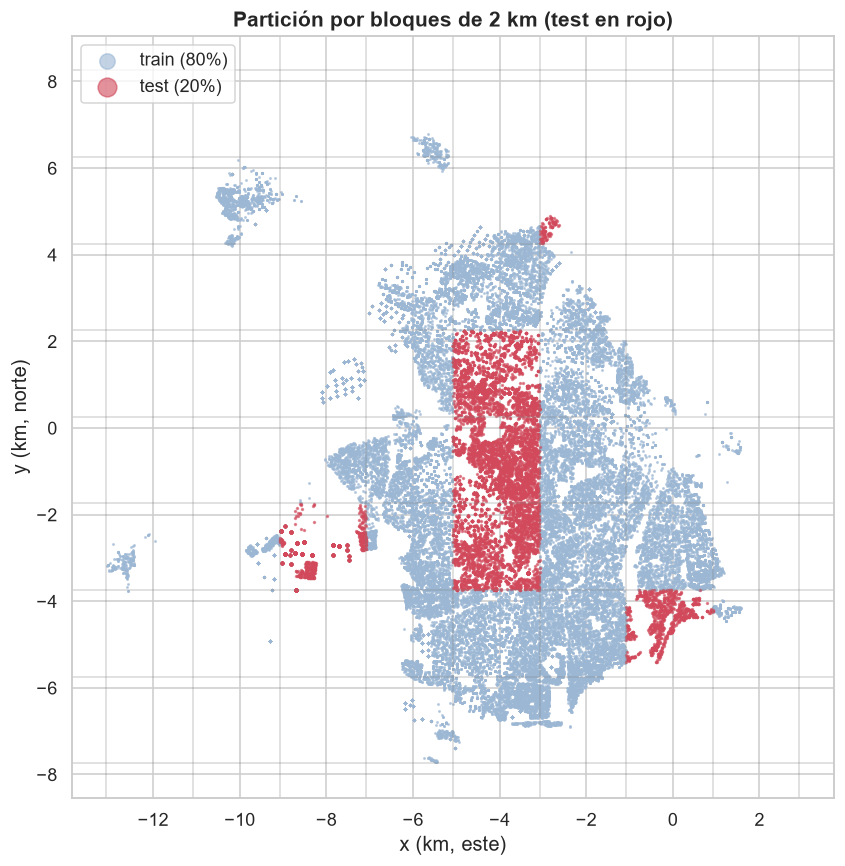

In [8]:
# Mapa de la partición: puntos de train (azul) y test (rojo) sobre la grilla de
# bloques de 2 km. Permite verificar visualmente que test son zonas compactas y
# repartidas por la ciudad, no puntos sueltos mezclados con train.
fig, ax = plt.subplots(figsize=(9, 9))
# Submuestra de hasta 60 000 puntos solo para dibujar rápido (semilla fija).
muestra = con.sample(min(60_000, len(con)), random_state=C.SEED)
# Test se dibuja después y un poco más grande para que resalte sobre train;
# la leyenda muestra el % de filas de cada conjunto calculado sobre 'con' completo.
for nombre, color, tam in [("train", "#9bb7d4", 1), ("test", "#d1495b", 1.5)]:
    s = muestra[muestra["particion"] == nombre]
    ax.scatter(s["x_km"], s["y_km"], s=tam, c=color, label=f"{nombre} ({(con.particion == nombre).mean():.0%})",
               alpha=0.6, rasterized=True)
# Líneas de la grilla: parten del mínimo de x e y, igual que asignar_bloques, para
# que coincidan con los bordes reales de los bloques (xs/ys no se usan después).
xs = np.arange(np.floor(con.x_km.min()), con.x_km.max() + C.TAM_BLOQUE_KM, C.TAM_BLOQUE_KM)
ys = np.arange(np.floor(con.y_km.min()), con.y_km.max() + C.TAM_BLOQUE_KM, C.TAM_BLOQUE_KM)
x0, y0 = con.x_km.min(), con.y_km.min()
for v in np.arange(x0, con.x_km.max() + C.TAM_BLOQUE_KM, C.TAM_BLOQUE_KM):
    ax.axvline(v, color="grey", lw=0.3)
for v in np.arange(y0, con.y_km.max() + C.TAM_BLOQUE_KM, C.TAM_BLOQUE_KM):
    ax.axhline(v, color="grey", lw=0.3)
G.ejes_mapa(ax, f"Partición por bloques de {C.TAM_BLOQUE_KM:.0f} km (test en rojo)")
ax.legend(markerscale=10, loc="upper left")   # marcadores de la leyenda agrandados
G.guardar(fig, "02_particion_mapa")
plt.show()

In [9]:
# Persistencia: se guarda el dataset de modelado con las columnas 'bloque' y
# 'particion' (parquet, o CSV si no hay motor parquet) para que los caps. 3 a 10
# lean exactamente la misma partición. Las filas sin coordenadas se guardan aparte,
# en el mismo formato, para analizar en el cap. 3 el sesgo de excluirlas.
# Las decisiones (tamaño de bloque, semilla) quedan en decisiones_eda.json con su
# motivo, para rastrear cada elección del modelado hasta el hallazgo que la justifica.
ruta = P.guardar_particion(con)
sin.to_parquet(C.CARPETA_PROCESADOS / "sin_coordenadas.parquet", index=False) \
    if ruta.suffix == ".parquet" else sin.to_csv(C.CARPETA_PROCESADOS / "sin_coordenadas.csv", index=False)
C.guardar_decision("tam_bloque_km", C.TAM_BLOQUE_KM,
                   "Bloques de 2 km: mayores que la escala de un barrio/edificio, de modo que "
                   "unidades vecinas casi idénticas no queden a ambos lados de la partición.")
C.guardar_decision("semilla", C.SEED, "Semilla única para partición, CV, muestreos y modelos.")
print(f"Guardado: {ruta.relative_to(C.RAIZ).as_posix()}")

[decisión registrada] tam_bloque_km = 2.0
   motivo: Bloques de 2 km: mayores que la escala de un barrio/edificio, de modo que unidades vecinas casi idénticas no queden a ambos lados de la partición.
[decisión registrada] semilla = 42
   motivo: Semilla única para partición, CV, muestreos y modelos.
Guardado: datos/procesados/dataset_modelado.parquet


```{admonition} Regla para el resto del libro
:class: important
Desde aquí, **todos** los capítulos de EDA (3 a 9) cargan únicamente
`particion == "train"` con `P.cargar_particion(solo="train")`. El conjunto de
prueba solo se vuelve a abrir en el capítulo 10, una única vez, para la
evaluación final del modelo ya decidido.
```